<a href="https://colab.research.google.com/github/EsatovinVictoria/ML_Semester5_EsatovinEbenhaezerVictoria/blob/main/Pertemuan_6/Praktikum_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Praktikum 2

In [1]:
!pip install faiss-cpu
#!pip install faiss-gpu

Exact NN (Flat) indices: [[105 482 632]] distances: [[0.0004 0.0004 0.0005]]
IVF+PQ indices: [[482 105 632]] distances: [[0.0004     0.00040144 0.00050158]]
Waktu Exact: 0.001661539077758789
Waktu IVF+PQ: 0.0011131763458251953


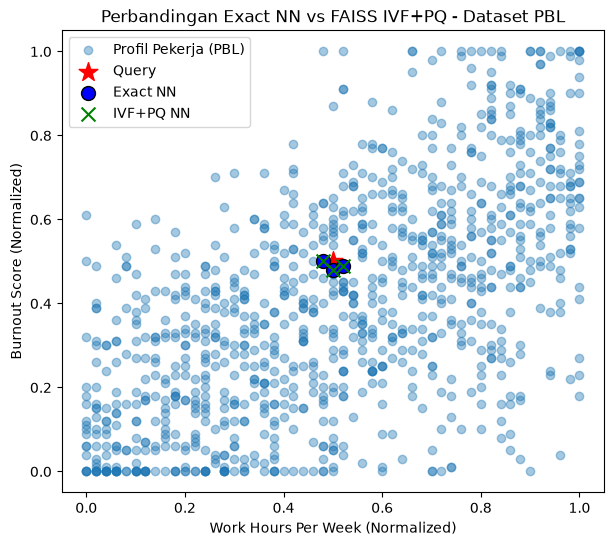

In [2]:
import pandas as pd
import numpy as np
import faiss
import matplotlib.pyplot as plt
import time
from sklearn.preprocessing import MinMaxScaler

# 1. Dataset 2D dari Dataset PBL
df = pd.read_csv('burnout_dataset1.csv')
features_2d = ['Work_Hours_Per_Week', 'Burnout_Score']
df_2d = df[features_2d].fillna(df[features_2d].mean(numeric_only=True))

scaler = MinMaxScaler()
X = scaler.fit_transform(df_2d.iloc[:1000]).astype('float32')
query = np.array([[0.5, 0.5]], dtype='float32')

# 2. Exact NN dengan IndexFlatL2
index_flat = faiss.IndexFlatL2(2)
index_flat.add(X)

start = time.time()
D_flat, I_flat = index_flat.search(query, 3)
end = time.time()
time_flat = end - start

# 3. IVF + PQ (Approximate)
nlist = 10
m = 2
quantizer = faiss.IndexFlatL2(2)
index_ivfpq = faiss.IndexIVFPQ(quantizer, 2, nlist, m, 8)

index_ivfpq.train(X)
index_ivfpq.add(X)

start = time.time()
D_ivfpq, I_ivfpq = index_ivfpq.search(query, 3)
end = time.time()
time_ivfpq = end - start

# 4. Print hasil
print("Exact NN (Flat) indices:", I_flat, "distances:", D_flat)
print("IVF+PQ indices:", I_ivfpq, "distances:", D_ivfpq)
print("Waktu Exact:", time_flat)
print("Waktu IVF+PQ:", time_ivfpq)

# 5. Visualisasi
plt.figure(figsize=(7, 6))
plt.scatter(X[:,0], X[:,1], alpha=0.4, label="Profil Pekerja (PBL)")
plt.scatter(query[:,0], query[:,1], c='red', marker='*', s=200, label="Query")
plt.scatter(X[I_flat[0],0], X[I_flat[0],1], c='blue', s=100, edgecolor='k', label="Exact NN")
plt.scatter(X[I_ivfpq[0],0], X[I_ivfpq[0],1], c='green', marker='x', s=100, label="IVF+PQ NN")
plt.xlabel("Work Hours Per Week (Normalized)")
plt.ylabel("Burnout Score (Normalized)")
plt.legend()
plt.title("Perbandingan Exact NN vs FAISS IVF+PQ - Dataset PBL")
plt.show()